###### CSE475 — Task 1: Exploratory Data Analysis
## UNSW-NB15 · Track 1 (Graph Neural Network)

**Group:** `07`
**Dataset:** UNSW-NB15 (original Argus/Bro-IDS feature set)
**Track:** 1 — GNN on network-flow data, hosts as nodes, flows as edges
**Submission:** 16/10/2026

---

### What this notebook delivers

Sections **A–H** required by the course brief, plus two analyses specific to our
graph-based project (**P1**, **P2**) and a split-feasibility check (**P3**).

| # | Content |
|---|---|
| A | Dataset summary table |
| B | Descriptive statistics |
| C | Data quality |
| D | Class balance |
| E | Feature distributions |
| F | Correlation and redundancy |
| G | PCA / t-SNE / UMAP projection |
| H | Interactive plots |
| P1 | Host cardinality — can we build a graph at all? |
| P2 | Identifier leakage evidence |
| P3 | Three-way host-disjoint split feasibility |

Every figure carries a title, axis labels, and a short **Reading:** note stating
what it shows. Unexplained figures earn no marks.

## 0 · Setup

Run this first. It imports everything, fixes the random seed, and sets plot
defaults so every figure is legible and consistently styled.

In [16]:
import os, sys, json, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---- plot defaults: readable in a printed report -------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "figure.autolayout": True,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "legend.frameon": False,
})
sns.set_palette("colorblind")

# ---- where figures and summary tables get written -----------------------
OUT = Path("figures"); OUT.mkdir(exist_ok=True)
TBL = Path("tables");  TBL.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure for the report and return its path."""
    p = OUT / f"{name}.png"
    fig.savefig(p, bbox_inches="tight")
    return p

def dump(df, name):
    """Save a table as CSV so it can be pasted into the report."""
    p = TBL / f"{name}.csv"
    df.to_csv(p, index=True)
    return p

def reading(text):
    """Print the one-or-two-line interpretation that must accompany a figure."""
    print("\nReading: " + text)

print("python     ", sys.version.split()[0])
print("pandas     ", pd.__version__)
print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)
print("seaborn    ", sns.__version__)

python      3.13.15
pandas      2.3.3
numpy       2.1.3
matplotlib  3.10.0
seaborn     0.13.2


## 0.1 · Locate the dataset files




In [17]:
SEARCH_ROOTS = ["/kaggle/input", ".", "data"]

found = []
for root in SEARCH_ROOTS:
    if not os.path.isdir(root):
        continue
    for dirpath, _, files in os.walk(root):
        for f in files:
            if f.lower().endswith((".csv", ".parquet")):
                fp = Path(dirpath) / f
                try:
                    mb = fp.stat().st_size / 1e6
                except OSError:
                    continue
                found.append({"file": f, "dir": dirpath, "size_MB": round(mb, 1)})

if not found:
    print("NO DATA FILES FOUND.")
    print("On Kaggle: click 'Add Data' (top right) and attach a UNSW-NB15 dataset.")
else:
    inv = pd.DataFrame(found).sort_values("size_MB", ascending=False).reset_index(drop=True)
    print(f"{len(inv)} data file(s) found:\n")
    print(inv.to_string())

8 data file(s) found:

                         file                                            dir  size_MB
0             UNSW-NB15_1.csv  /kaggle/input/datasets/mrwellsdavid/unsw-nb15    169.0
1             UNSW-NB15_2.csv  /kaggle/input/datasets/mrwellsdavid/unsw-nb15    165.2
2             UNSW-NB15_3.csv  /kaggle/input/datasets/mrwellsdavid/unsw-nb15    154.6
3             UNSW-NB15_4.csv  /kaggle/input/datasets/mrwellsdavid/unsw-nb15     97.6
4   UNSW_NB15_testing-set.csv  /kaggle/input/datasets/mrwellsdavid/unsw-nb15     32.3
5  UNSW_NB15_training-set.csv  /kaggle/input/datasets/mrwellsdavid/unsw-nb15     15.4
6   UNSW-NB15_LIST_EVENTS.csv  /kaggle/input/datasets/mrwellsdavid/unsw-nb15      0.0
7      NUSW-NB15_features.csv  /kaggle/input/datasets/mrwellsdavid/unsw-nb15      0.0


## 0.2 · ⚠ Which UNSW-NB15 files do we have? This decides the whole project

UNSW-NB15 ships in two shapes, and **they are not interchangeable for us**.

| Shape | Files | Features | Has IP / port columns? |
|---|---|---|---|
| **Partitioned** | `UNSW_NB15_training-set.csv`, `UNSW_NB15_testing-set.csv` | 45 | **No** |
| **Full** | `UNSW-NB15_1.csv` … `UNSW-NB15_4.csv` | 49 | **Yes** — `srcip`, `sport`, `dstip`, `dsport` |

Our Track 1 design makes **hosts the nodes** and **flows the edges**. Node identity
comes from the IP columns. The partitioned files do not contain them, so:

> **If only the partitioned files are attached, we cannot build a host graph.**

The cell below checks this and prints a verdict. If it says the IP columns are
missing, attach a dataset that includes the four full CSVs before Task 2 — and
record the finding in the Task 1 report, because it is a genuine constraint
discovered during EDA, which is exactly what Task 1 is for.

Note: IPs are used **only** to define nodes and edges. They are never fed to the
model as features (see §P2).

In [18]:
# Canonical 49-column header for the full UNSW-NB15_1..4.csv files, which ship
# WITHOUT a header row. Order follows NUSW-NB15_features.csv.
FULL_COLS = [
    "srcip","sport","dstip","dsport","proto","state","dur","sbytes","dbytes",
    "sttl","dttl","sloss","dloss","service","sload","dload","spkts","dpkts",
    "swin","dwin","stcpb","dtcpb","smeansz","dmeansz","trans_depth",
    "res_bdy_len","sjit","djit","stime","ltime","sintpkt","dintpkt","tcprtt",
    "synack","ackdat","is_sm_ips_ports","ct_state_ttl","ct_flw_http_mthd",
    "is_ftp_login","ct_ftp_cmd","ct_srv_src","ct_srv_dst","ct_dst_ltm",
    "ct_src_ltm","ct_src_dport_ltm","ct_dst_sport_ltm","ct_dst_src_ltm",
    "attack_cat","label",
]

IP_COLS   = ["srcip", "dstip"]
PORT_COLS = ["sport", "dsport"]

def classify(fname):
    f = fname.lower()
    if "training-set" in f or "training_set" in f:  return "partitioned_train"
    if "testing-set"  in f or "testing_set"  in f:  return "partitioned_test"
    if "features"     in f:                          return "feature_list"
    if "list_events"  in f or "list-events"  in f:   return "event_list"
    if "unsw-nb15_" in f and any(d in f for d in "1234"): return "full_part"
    return "other"

if found:
    inv["kind"] = inv["file"].map(classify)
    print(inv[["file", "size_MB", "kind"]].to_string(index=False), "\n")

    kinds = set(inv["kind"])
    has_full = "full_part" in kinds
    has_part = {"partitioned_train", "partitioned_test"} & kinds

    print("=" * 68)
    if has_full:
        print("VERDICT: full CSVs present -> IP columns available.")
        print("         A host graph CAN be built. Use these for Task 2.")
    elif has_part:
        print("VERDICT: ONLY the partitioned CSVs are present.")
        print("         These have NO srcip/dstip columns.")
        print("         -> A host-based graph CANNOT be built from them.")
        print("         -> EDA below still runs in full and is valid for Task 1.")
        print("         -> ACTION: attach the full UNSW-NB15_1..4.csv before Task 2,")
        print("            or ask the UTA which files the project should use.")
    else:
        print("VERDICT: no recognised UNSW-NB15 file. Check the attached dataset.")
    print("=" * 68)

                      file  size_MB              kind
           UNSW-NB15_1.csv    169.0         full_part
           UNSW-NB15_2.csv    165.2         full_part
           UNSW-NB15_3.csv    154.6         full_part
           UNSW-NB15_4.csv     97.6         full_part
 UNSW_NB15_testing-set.csv     32.3  partitioned_test
UNSW_NB15_training-set.csv     15.4 partitioned_train
 UNSW-NB15_LIST_EVENTS.csv      0.0        event_list
    NUSW-NB15_features.csv      0.0      feature_list 

VERDICT: full CSVs present -> IP columns available.
         A host graph CAN be built. Use these for Task 2.


## 0.3 · Load the data

Loads whichever shape is available, preferring the full CSVs because they carry
the IP columns our project needs. Set `MAX_ROWS` to cap memory if the kernel
struggles; set it to `None` to load everything.

In [19]:
MAX_ROWS = 700_000
PREFER_FULL = True

def _safe_read(p, **kw):
    """UNSW-NB15 files are a mix of utf-8 and latin-1."""
    for enc in ("utf-8", "latin-1", "cp1252"):
        try:
            return pd.read_csv(p, encoding=enc, **kw)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(p, encoding="latin-1", encoding_errors="replace", **kw)

def _read_full(paths, nrows_each):
    frames = []
    for p in paths:
        head = _safe_read(p, nrows=1, header=None, dtype=str)
        headerless = str(head.iloc[0, 0]).count(".") >= 3
        df_ = _safe_read(p, header=None if headerless else 0,
                         names=FULL_COLS if headerless else None,
                         nrows=nrows_each, low_memory=False)
        if not headerless and len(df_.columns) == len(FULL_COLS):
            df_.columns = FULL_COLS
        frames.append(df_); print(f"  loaded {Path(p).name}: {df_.shape}")
    return pd.concat(frames, ignore_index=True)

df = None; SOURCE = None
full_paths = sorted(str(Path(r["dir"]) / r["file"])
                    for _, r in inv[inv["kind"] == "full_part"].iterrows())
print("full CSVs detected:", [Path(p).name for p in full_paths] or "NONE")

if PREFER_FULL and full_paths:
    per = None if MAX_ROWS is None else max(1, MAX_ROWS // len(full_paths))
    df = _read_full(full_paths, per); SOURCE = "full"
else:
    parts = []
    for kind, tag in (("partitioned_train", "train"), ("partitioned_test", "test")):
        for _, r in inv[inv["kind"] == kind].iterrows():
            p = Path(r["dir"]) / r["file"]
            d = _safe_read(p, nrows=MAX_ROWS, low_memory=False)
            d["_partition"] = tag; parts.append(d)
            print(f"  loaded {p.name}: {d.shape}")
    if parts:
        df = pd.concat(parts, ignore_index=True); SOURCE = "partitioned"

if df is None:
    raise SystemExit("No data loaded — attach mrwellsdavid/unsw-nb15.")

df.columns = [c.strip() for c in df.columns]

if "attack_cat" in df.columns:
    s = df["attack_cat"].astype(object)
    s = s.where(df["attack_cat"].notna(), "Normal").astype(str).str.strip()
    df["attack_cat"] = s.replace({"": "Normal", "nan": "Normal", "NaN": "Normal",
                                  "None": "Normal", "-": "Normal",
                                  "Backdoors": "Backdoor"})

print(f"\nSOURCE = {SOURCE}")
print(f"shape  = {df.shape[0]:,} rows x {df.shape[1]} columns")
HAS_IP   = all(c in df.columns for c in IP_COLS)
HAS_PORT = all(c in df.columns for c in PORT_COLS)
print(f"IP columns present   : {HAS_IP}")
print(f"Port columns present : {HAS_PORT}")

full CSVs detected: ['UNSW-NB15_1.csv', 'UNSW-NB15_2.csv', 'UNSW-NB15_3.csv', 'UNSW-NB15_4.csv']
  loaded UNSW-NB15_1.csv: (175000, 49)
  loaded UNSW-NB15_2.csv: (175000, 49)
  loaded UNSW-NB15_3.csv: (175000, 49)
  loaded UNSW-NB15_4.csv: (175000, 49)

SOURCE = full
shape  = 700,000 rows x 49 columns
IP columns present   : True
Port columns present : True


In [20]:
# Column roles, used by every section below.
TARGET_BIN  = "label"
TARGET_MULTI = "attack_cat" if "attack_cat" in df.columns else None

# Identifier-like columns: usable for GRAPH STRUCTURE, never as model features.
ID_LIKE = [c for c in ["srcip","sport","dstip","dsport","stime","ltime","id"]
           if c in df.columns]

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

for t in [TARGET_BIN, TARGET_MULTI, "_partition"]:
    if t in num_cols: num_cols.remove(t)
    if t in cat_cols: cat_cols.remove(t)

# Features we would actually model on.
FEAT_NUM = [c for c in num_cols if c not in ID_LIKE]
FEAT_CAT = [c for c in cat_cols if c not in ID_LIKE]

print(f"numeric features   : {len(FEAT_NUM)}")
print(f"categorical features: {len(FEAT_CAT)}  -> {FEAT_CAT}")
print(f"identifier-like     : {ID_LIKE}   (structure only, never features)")
print(f"binary target       : {TARGET_BIN}")
print(f"multiclass target   : {TARGET_MULTI}")

numeric features   : 37
categorical features: 4  -> ['proto', 'state', 'service', 'ct_ftp_cmd']
identifier-like     : ['srcip', 'sport', 'dstip', 'dsport', 'stime', 'ltime']   (structure only, never features)
binary target       : label
multiclass target   : attack_cat


## A · Dataset summary table

The brief asks for name, source, area, samples, classes, feature count and type,
hosts, balance, missing values, and duplicates — in one table.

In [21]:
n_hosts = (pd.concat([df["srcip"], df["dstip"]]).nunique() if HAS_IP else None)

summary = {
    "Dataset name":          "UNSW-NB15",
    "Source":                "ACCS, UNSW Canberra (Moustafa & Slay, MilCIS 2015)",
    "Application area":      "Network intrusion detection (NIDS)",
    "File shape loaded":     SOURCE,
    "Samples (rows)":        f"{len(df):,}",
    "Total columns":         df.shape[1],
    "Numeric features":      len(FEAT_NUM),
    "Categorical features":  len(FEAT_CAT),
    "Identifier-like cols":  len(ID_LIKE),
    "Problem type":          "Binary + 10-class multiclass classification",
    "Binary classes":        "2 (0 = normal, 1 = attack)",
    "Multiclass classes":    (df[TARGET_MULTI].nunique() if TARGET_MULTI else "n/a"),
    "Distinct hosts":        (f"{n_hosts:,}" if n_hosts else "n/a (no IP columns)"),
    "Missing values (total)": f"{int(df.isna().sum().sum()):,}",
    "Columns with missing":  int((df.isna().sum() > 0).sum()),
    "Duplicate rows":        f"{int(df.duplicated().sum()):,}",
}

A = pd.DataFrame(summary.items(), columns=["Property", "Value"]).set_index("Property")
dump(A, "A_dataset_summary")
A

,Value
Property,
Dataset name,UNSW-NB15
Source,"ACCS, UNSW Canberra (Moustafa & Slay, MilCIS 2..."
Application area,Network intrusion detection (NIDS)
File shape loaded,full
Samples (rows),"700,000"
Total columns,49
Numeric features,37
Categorical features,4
Identifier-like cols,6


In [22]:
# Per-column reference table: dtype, missing, unique, example value.
schema = pd.DataFrame({
    "dtype":    df.dtypes.astype(str),
    "missing":  df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(3),
    "n_unique": df.nunique(),
    "example":  [df[c].dropna().iloc[0] if df[c].notna().any() else None
                 for c in df.columns],
})
schema["role"] = np.where(schema.index.isin(ID_LIKE), "identifier",
                   np.where(schema.index.isin([TARGET_BIN, TARGET_MULTI]), "target",
                            "feature"))
dump(schema, "A_column_schema")
schema

,dtype,missing,missing_%,n_unique,example,role
srcip,object,0,0.000,42,59.166.0.0,identifier
sport,object,0,0.000,122847,1390,identifier
dstip,object,0,0.000,46,149.171.126.6,identifier
dsport,object,0,0.000,91666,53,identifier
proto,object,0,0.000,135,udp,feature
state,object,0,0.000,16,CON,feature
dur,float64,0,0.000,225879,0.001055,feature
sbytes,int64,0,0.000,6850,132,feature
dbytes,int64,0,0.000,7730,164,feature
sttl,int64,0,0.000,13,31,feature


## B · Descriptive statistics

Mean, median, standard deviation, min/max, quartiles, **skewness**, **kurtosis**
and an outlier count per numeric feature. Skew and kurtosis matter here: heavily
skewed features need scaling or a log transform before any distance-based model.

In [23]:
d = df[FEAT_NUM]

B = pd.DataFrame({
    "mean":   d.mean(),
    "median": d.median(),
    "std":    d.std(),
    "min":    d.min(),
    "q25":    d.quantile(.25),
    "q50":    d.quantile(.50),
    "q75":    d.quantile(.75),
    "max":    d.max(),
    "skew":   d.skew(),
    "kurtosis": d.kurtosis(),
})

# Outliers by the 1.5 x IQR rule.
q1, q3 = d.quantile(.25), d.quantile(.75)
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
B["outliers"]   = ((d < lo) | (d > hi)).sum()
B["outliers_%"] = (B["outliers"] / len(d) * 100).round(2)

B = B.round(3)
dump(B, "B_descriptive_statistics")

print(f"Features with |skew| > 2      : {(B['skew'].abs() > 2).sum()} of {len(B)}")
print(f"Features with kurtosis > 10   : {(B['kurtosis'] > 10).sum()} of {len(B)}")
print(f"Features with >5% outliers    : {(B['outliers_%'] > 5).sum()} of {len(B)}")
reading("Most flow features are strongly right-skewed and heavy-tailed, because "
        "a few flows carry enormous byte and packet counts. Scaling is required, "
        "and it must be fit on training data only.")
B

Features with |skew| > 2      : 29 of 37
Features with kurtosis > 10   : 22 of 37
Features with >5% outliers    : 30 of 37

Reading: Most flow features are strongly right-skewed and heavy-tailed, because a few flows carry enormous byte and packet counts. Scaling is required, and it must be fit on training data only.


,mean,median,std,min,q25,q50,q75,max,skew,kurtosis,outliers,outliers_%
dur,5.880000e-01,1.200000e-02,3.419000e+00,0.0,0.001,1.200000e-02,1.610000e-01,6.000000e+01,12.183,169.449,131092,18.73
sbytes,4.226327e+03,1.036000e+03,6.462254e+04,0.0,200.000,1.036000e+03,2.974000e+03,1.367739e+07,132.736,20339.890,73019,10.43
dbytes,3.225848e+04,1.644000e+03,1.499387e+05,0.0,162.000,1.644000e+03,1.016800e+04,1.465555e+07,10.696,389.577,117227,16.75
sttl,6.729700e+01,3.100000e+01,7.820900e+01,0.0,31.000,3.100000e+01,6.000000e+01,2.550000e+02,1.927,1.818,103060,14.72
dttl,3.119800e+01,2.900000e+01,4.679900e+01,0.0,29.000,2.900000e+01,2.900000e+01,2.540000e+02,4.143,16.921,195782,27.97
sloss,4.850000e+00,2.000000e+00,2.526300e+01,0.0,0.000,2.000000e+00,7.000000e+00,5.096000e+03,116.854,17110.687,51536,7.36
dloss,1.459900e+01,2.000000e+00,5.280700e+01,0.0,0.000,2.000000e+00,1.100000e+01,5.484000e+03,11.206,476.510,62457,8.92
sload,4.432434e+07,6.357748e+05,1.285965e+08,0.0,183667.684,6.357748e+05,5.923716e+06,5.988000e+09,6.938,107.689,159549,22.79
dload,2.348556e+06,4.099235e+05,4.191474e+06,0.0,2845.648,4.099235e+05,2.490456e+06,4.807207e+07,2.027,2.974,100594,14.37
spkts,3.058400e+01,1.000000e+01,7.624300e+01,0.0,2.000,1.000000e+01,4.200000e+01,1.020000e+04,36.330,3315.841,35859,5.12


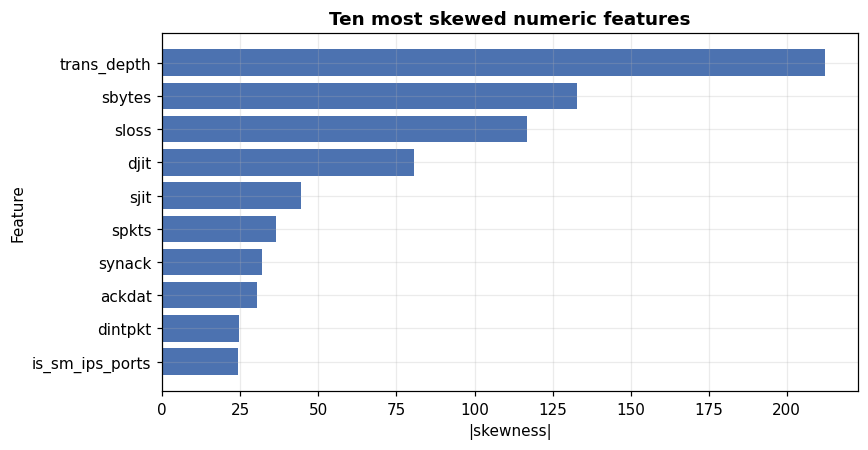


Reading: 'trans_depth' is the most skewed feature (|skew| = 212.2). Features above |skew| = 2 are candidates for a log1p transform before modelling.


In [24]:
# The ten most skewed features — these are the ones a log1p transform helps most.
top_skew = B["skew"].abs().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top_skew.index[::-1], top_skew.values[::-1], color="#4C72B0")
ax.set_title("Ten most skewed numeric features")
ax.set_xlabel("|skewness|")
ax.set_ylabel("Feature")
save(fig, "B_top_skew"); plt.show()
reading(f"'{top_skew.index[0]}' is the most skewed feature (|skew| = "
        f"{top_skew.iloc[0]:.1f}). Features above |skew| = 2 are candidates for "
        "a log1p transform before modelling.")

## C · Data quality

Four checks, and for each one a statement of **what it changes about preprocessing
or evaluation** — the deck is explicit that a finding without that statement is
incomplete.

1. Missing values
2. Duplicate rows
3. Near-constant features
4. Highly correlated feature pairs

In [25]:
print("=" * 60); print("C1 · MISSING VALUES"); print("=" * 60)

miss = (df.isna().sum().loc[lambda s: s > 0]
          .sort_values(ascending=False).to_frame("missing"))
if len(miss):
    miss["missing_%"] = (miss["missing"] / len(df) * 100).round(3)
    print(miss.to_string())
    dump(miss, "C1_missing")
    reading("Columns with missing values need an imputer. The imputer must be "
            "fit on the training split only, and refit inside every CV fold.")
else:
    print("No missing values.")
    reading("No imputation needed, which removes one source of leakage.")

C1 · MISSING VALUES
                  missing  missing_%
is_ftp_login       345104     49.301
ct_flw_http_mthd   330492     47.213

Reading: Columns with missing values need an imputer. The imputer must be fit on the training split only, and refit inside every CV fold.


In [26]:
print("=" * 60); print("C2 · DUPLICATES"); print("=" * 60)

n_dup = int(df.duplicated().sum())
print(f"Fully duplicated rows: {n_dup:,}  ({n_dup/len(df)*100:.3f}%)")

# Duplicates ignoring identifier columns are more meaningful: identical traffic
# measurements from different hosts or times.
if ID_LIKE:
    feat_only = [c for c in df.columns if c not in ID_LIKE]
    n_dup_feat = int(df[feat_only].duplicated().sum())
    print(f"Duplicates ignoring identifiers: {n_dup_feat:,} "
          f"({n_dup_feat/len(df)*100:.3f}%)")
    reading("Rows identical once identifiers are dropped are genuinely "
            "indistinguishable to the model. If such a pair straddles the "
            "train/test boundary the test score is inflated, so de-duplicate "
            "BEFORE splitting, not after.")
else:
    reading("Duplicate rows that straddle the split inflate the test score. "
            "De-duplicate before splitting.")

C2 · DUPLICATES
Fully duplicated rows: 142,474  (20.353%)
Duplicates ignoring identifiers: 150,284 (21.469%)

Reading: Rows identical once identifiers are dropped are genuinely indistinguishable to the model. If such a pair straddles the train/test boundary the test score is inflated, so de-duplicate BEFORE splitting, not after.


In [27]:
print("=" * 60); print("C3 · NEAR-CONSTANT FEATURES"); print("=" * 60)

NEAR_CONST = 0.99   # one value covers >= 99% of rows
rows = []
for c in FEAT_NUM + FEAT_CAT:
    vc = df[c].value_counts(normalize=True, dropna=False)
    if len(vc) and vc.iloc[0] >= NEAR_CONST:
        rows.append({"feature": c, "top_value": vc.index[0],
                     "share_%": round(vc.iloc[0] * 100, 2),
                     "n_unique": df[c].nunique()})

C3 = pd.DataFrame(rows)
if len(C3):
    print(C3.sort_values("share_%", ascending=False).to_string(index=False))
    dump(C3, "C3_near_constant")
    reading(f"{len(C3)} feature(s) are near-constant and carry almost no "
            "information. They can be dropped to reduce dimensionality, but "
            "check per-class behaviour first: a flag that is rare overall may "
            "still be decisive for a rare attack class.")
else:
    print("No near-constant features at the 99% threshold.")
    reading("Every feature varies, so none can be dropped on this ground.")

C3 · NEAR-CONSTANT FEATURES
        feature  top_value  share_%  n_unique
is_sm_ips_ports          0    99.83         2

Reading: 1 feature(s) are near-constant and carry almost no information. They can be dropped to reduce dimensionality, but check per-class behaviour first: a flag that is rare overall may still be decisive for a rare attack class.


In [28]:
print("=" * 60); print("C4 · HIGHLY CORRELATED PAIRS"); print("=" * 60)

CORR_T = 0.95
cm = df[FEAT_NUM].corr(numeric_only=True).abs()
upper = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool))

pairs = (upper.stack().loc[lambda s: s >= CORR_T]
              .sort_values(ascending=False)
              .rename("abs_corr").reset_index())
pairs.columns = ["feature_1", "feature_2", "abs_corr"]

if len(pairs):
    print(pairs.round(4).to_string(index=False))
    dump(pairs, "C4_correlated_pairs")
    redundant = sorted(set(pairs["feature_2"]))
    print(f"\nRedundant candidates ({len(redundant)}): {redundant}")
    reading(f"{len(pairs)} pair(s) exceed |r| = {CORR_T}. Keeping both members "
            "of a pair inflates their joint influence and destabilises "
            "coefficient-based explanations, so one of each pair should be "
            "dropped before SHAP analysis in Task 3.")
else:
    print(f"No pairs above |r| = {CORR_T}.")
    redundant = []
    reading("No strictly redundant pairs at this threshold; see §F for the "
            "full correlation structure.")

C4 · HIGHLY CORRELATED PAIRS
 feature_1        feature_2  abs_corr
      swin             dwin    0.9959
    dbytes            dloss    0.9921
     dloss            dpkts    0.9915
ct_dst_ltm ct_src_dport_ltm    0.9775
    dbytes            dpkts    0.9716
ct_srv_src       ct_srv_dst    0.9681
    sbytes            sloss    0.9679
ct_src_ltm ct_src_dport_ltm    0.9674
ct_dst_ltm       ct_src_ltm    0.9614
ct_srv_dst   ct_dst_src_ltm    0.9600
ct_srv_src   ct_dst_src_ltm    0.9534

Redundant candidates (8): ['ct_dst_src_ltm', 'ct_src_dport_ltm', 'ct_src_ltm', 'ct_srv_dst', 'dloss', 'dpkts', 'dwin', 'sloss']

Reading: 11 pair(s) exceed |r| = 0.95. Keeping both members of a pair inflates their joint influence and destabilises coefficient-based explanations, so one of each pair should be dropped before SHAP analysis in Task 3.


## D · Class balance

Counts, a bar chart, the majority-to-minority ratio, and — the part that earns
the marks — **what the imbalance does to our choice of metric**.

In [29]:
print("Binary target:")
vb = df[TARGET_BIN].value_counts().sort_index()
for k, v in vb.items():
    print(f"  {k} ({'normal' if k == 0 else 'attack'}): {v:>9,}  ({v/len(df)*100:5.2f}%)")

D = None
if TARGET_MULTI:
    D = df[TARGET_MULTI].value_counts().to_frame("count")
    D["share_%"] = (D["count"] / len(df) * 100).round(3)
    D["ratio_to_smallest"] = (D["count"] / D["count"].min()).round(1)
    dump(D, "D_class_balance")
    print("\nMulticlass target:")
    print(D.to_string())

    imb = D["count"].max() / D["count"].min()
    print(f"\nMajority-to-minority ratio: {imb:,.1f} : 1")

Binary target:
  0 (normal):   600,079  (85.73%)
  1 (attack):    99,921  (14.27%)

Multiclass target:
                 count  share_%  ratio_to_smallest
attack_cat                                        
Normal          600079   85.726            11322.2
Generic          67565    9.652             1274.8
Exploits         13052    1.865              246.3
Fuzzers           8824    1.261              166.5
Reconnaissance    4189    0.598               79.0
DoS               3899    0.557               73.6
Analysis           945    0.135               17.8
Backdoor           907    0.130               17.1
Shellcode          487    0.070                9.2
Worms               53    0.008                1.0

Majority-to-minority ratio: 11,322.2 : 1


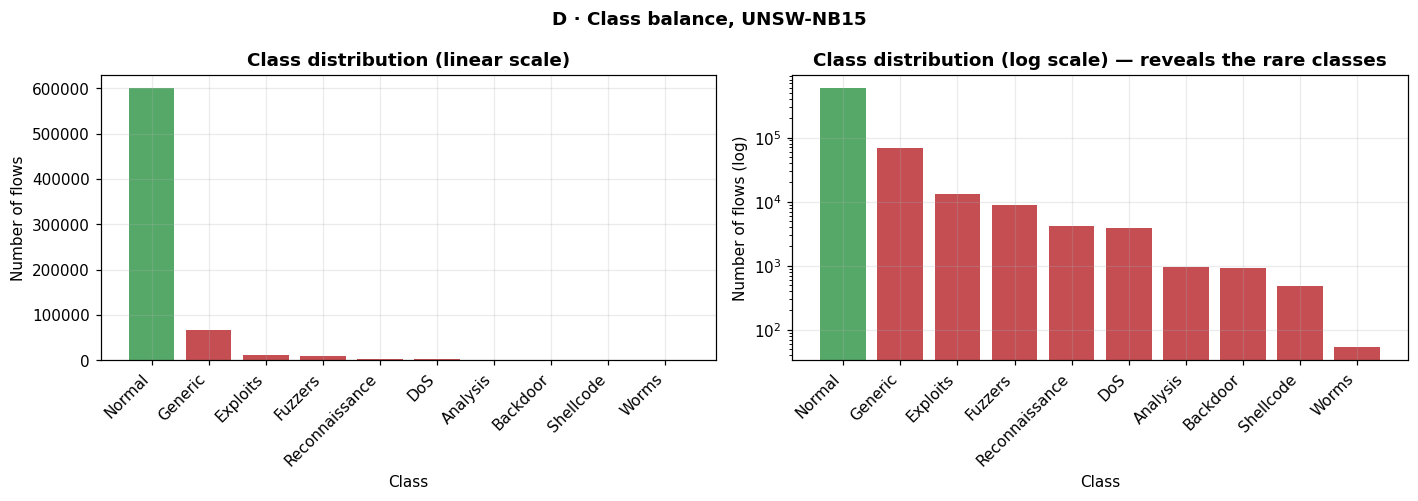


Reading: 'Normal' holds 600,079 flows while 'Worms' holds only 53 — a ratio of 11,322:1. The linear plot makes the rare classes invisible, which is precisely why overall accuracy is the wrong metric: a model that ignores every rare class entirely still scores well on it. We therefore judge on macro-F1 and per-class recall, as the brief requires for imbalanced data.


In [30]:
if D is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

    order = D.index.tolist()
    colors = ["#55A868" if c == "Normal" else "#C44E52" for c in order]

    axes[0].bar(range(len(D)), D["count"].values, color=colors)
    axes[0].set_xticks(range(len(D)))
    axes[0].set_xticklabels(order, rotation=45, ha="right")
    axes[0].set_title("Class distribution (linear scale)")
    axes[0].set_xlabel("Class"); axes[0].set_ylabel("Number of flows")

    axes[1].bar(range(len(D)), D["count"].values, color=colors)
    axes[1].set_yscale("log")
    axes[1].set_xticks(range(len(D)))
    axes[1].set_xticklabels(order, rotation=45, ha="right")
    axes[1].set_title("Class distribution (log scale) — reveals the rare classes")
    axes[1].set_xlabel("Class"); axes[1].set_ylabel("Number of flows (log)")

    fig.suptitle("D · Class balance, UNSW-NB15", fontweight="bold")
    save(fig, "D_class_balance"); plt.show()

    big, small = D.index[0], D.index[-1]
    reading(f"'{big}' holds {D.loc[big,'count']:,} flows while '{small}' holds only "
            f"{D.loc[small,'count']:,} — a ratio of "
            f"{D['count'].max()/D['count'].min():,.0f}:1. The linear plot makes the "
            "rare classes invisible, which is precisely why overall accuracy is "
            "the wrong metric: a model that ignores every rare class entirely "
            "still scores well on it. We therefore judge on macro-F1 and "
            "per-class recall, as the brief requires for imbalanced data.")

In [31]:
# What accuracy would a do-nothing model score? This number belongs in the report.
if D is not None:
    maj = D["count"].max() / D["count"].sum()
    print(f"Majority-class baseline accuracy : {maj*100:.2f}%")
    print(f"Majority-class baseline macro-F1 : "
          f"{(2*maj/(1+maj))/len(D)*100:.2f}%  (approx.)")
    print("\nAny model we build must be judged against the SECOND number, not the first.")

Majority-class baseline accuracy : 85.73%
Majority-class baseline macro-F1 : 9.23%  (approx.)

Any model we build must be judged against the SECOND number, not the first.


## E · Feature distributions

Histograms, boxplots and violin plots for the most informative numeric features.
The question each plot answers is the same: **do the classes separate on this
feature?**

Features are ranked by ANOVA F-statistic against the multiclass target, so we
plot the ones that actually discriminate rather than an arbitrary first six.

In [32]:
from sklearn.feature_selection import f_classif

y_multi = df[TARGET_MULTI] if TARGET_MULTI else df[TARGET_BIN]

# A clean numeric matrix reused by E, G, P2 and P3: no inf, no NaN, no
# all-missing columns (median-imputed columns that were wholly NaN stay NaN).
Xs = df[FEAT_NUM].replace([np.inf, -np.inf], np.nan)
Xs = Xs.fillna(Xs.median()).fillna(0.0)
assert not Xs.isna().any().any(), "Xs still contains NaN"
assert not y_multi.isna().any(), "target contains NaN"

F, p = f_classif(Xs, y_multi)
rank = (pd.DataFrame({"feature": FEAT_NUM, "F": F, "p": p})
          .sort_values("F", ascending=False).reset_index(drop=True))
dump(rank, "E_feature_discriminative_rank")

print("Top 12 features by ANOVA F against attack category:")
print(rank.head(12).to_string(index=False))
TOPK = rank["feature"].head(6).tolist()
reading(f"'{rank.iloc[0]['feature']}' is the single most discriminative feature. "
        "These rankings tell us which features a flat baseline will lean on, "
        "which is the comparison our graph model has to beat.")

Top 12 features by ANOVA F against attack category:
         feature             F   p
            sttl 376955.192485 0.0
    ct_state_ttl 218826.928958 0.0
            dttl  39464.775831 0.0
ct_dst_sport_ltm  25078.495366 0.0
  ct_dst_src_ltm  24656.895756 0.0
      ct_srv_dst  22333.336340 0.0
      ct_srv_src  21716.737899 0.0
ct_src_dport_ltm  21014.026717 0.0
      ct_dst_ltm  18417.014118 0.0
      ct_src_ltm  17823.769341 0.0
            swin  12343.239532 0.0
            dwin  12222.014186 0.0

Reading: 'sttl' is the single most discriminative feature. These rankings tell us which features a flat baseline will lean on, which is the comparison our graph model has to beat.


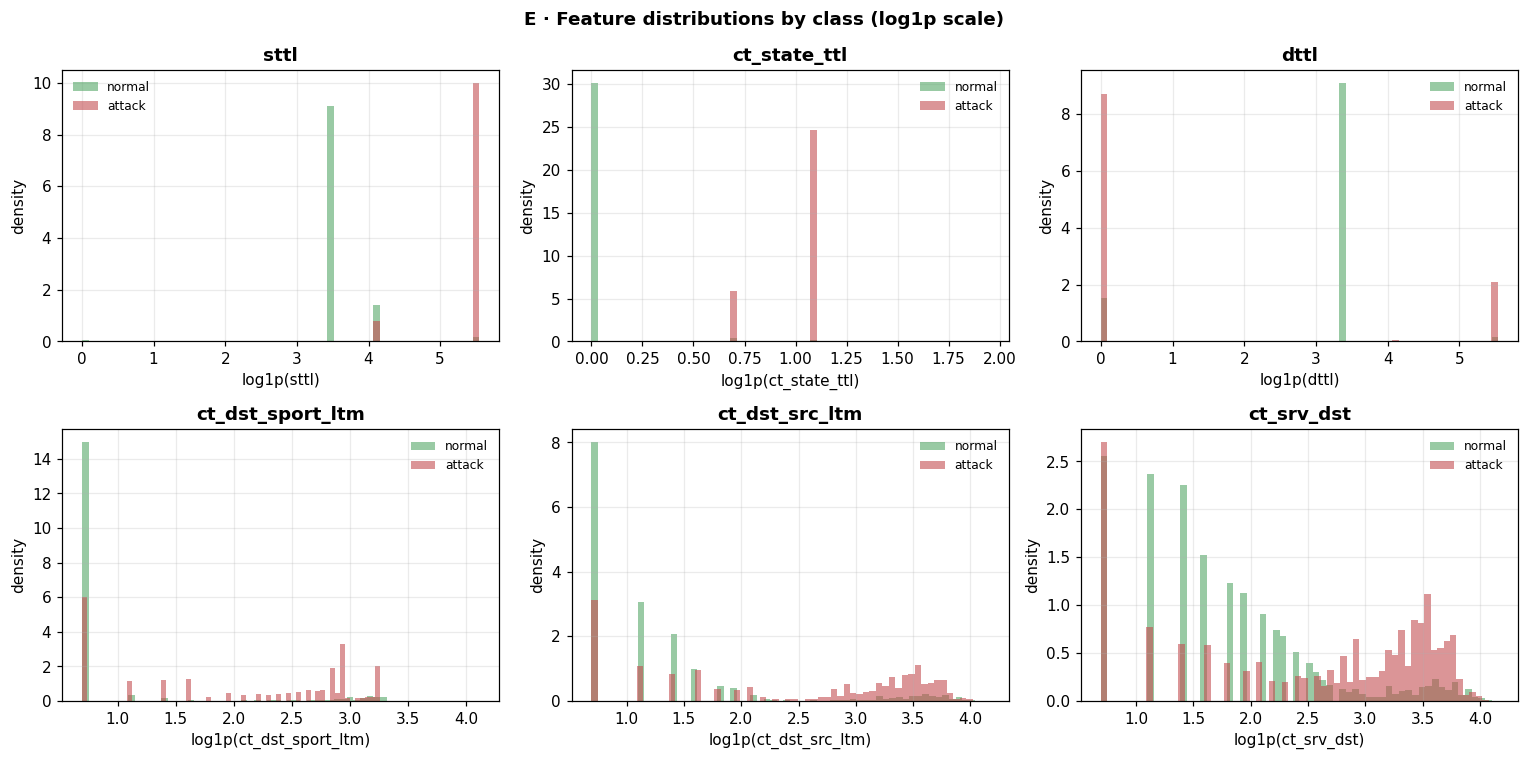


Reading: Where the green and red curves sit apart, a flat model can separate normal from attack on that feature alone. Where they overlap, the class must be inferred from feature combinations — or, in our case, from the host's connection pattern.


In [33]:
# Histograms, log1p-scaled because the raw distributions are extremely skewed.
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), TOPK):
    for lab, color in [(0, "#55A868"), (1, "#C44E52")]:
        v = df.loc[df[TARGET_BIN] == lab, c].replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(np.log1p(v.clip(lower=0)), bins=60, alpha=.6, density=True,
                color=color, label="normal" if lab == 0 else "attack")
    ax.set_title(c); ax.set_xlabel(f"log1p({c})"); ax.set_ylabel("density")
    ax.legend(fontsize=8)
fig.suptitle("E · Feature distributions by class (log1p scale)", fontweight="bold")
save(fig, "E_histograms"); plt.show()
reading("Where the green and red curves sit apart, a flat model can separate "
        "normal from attack on that feature alone. Where they overlap, the "
        "class must be inferred from feature combinations — or, in our case, "
        "from the host's connection pattern.")

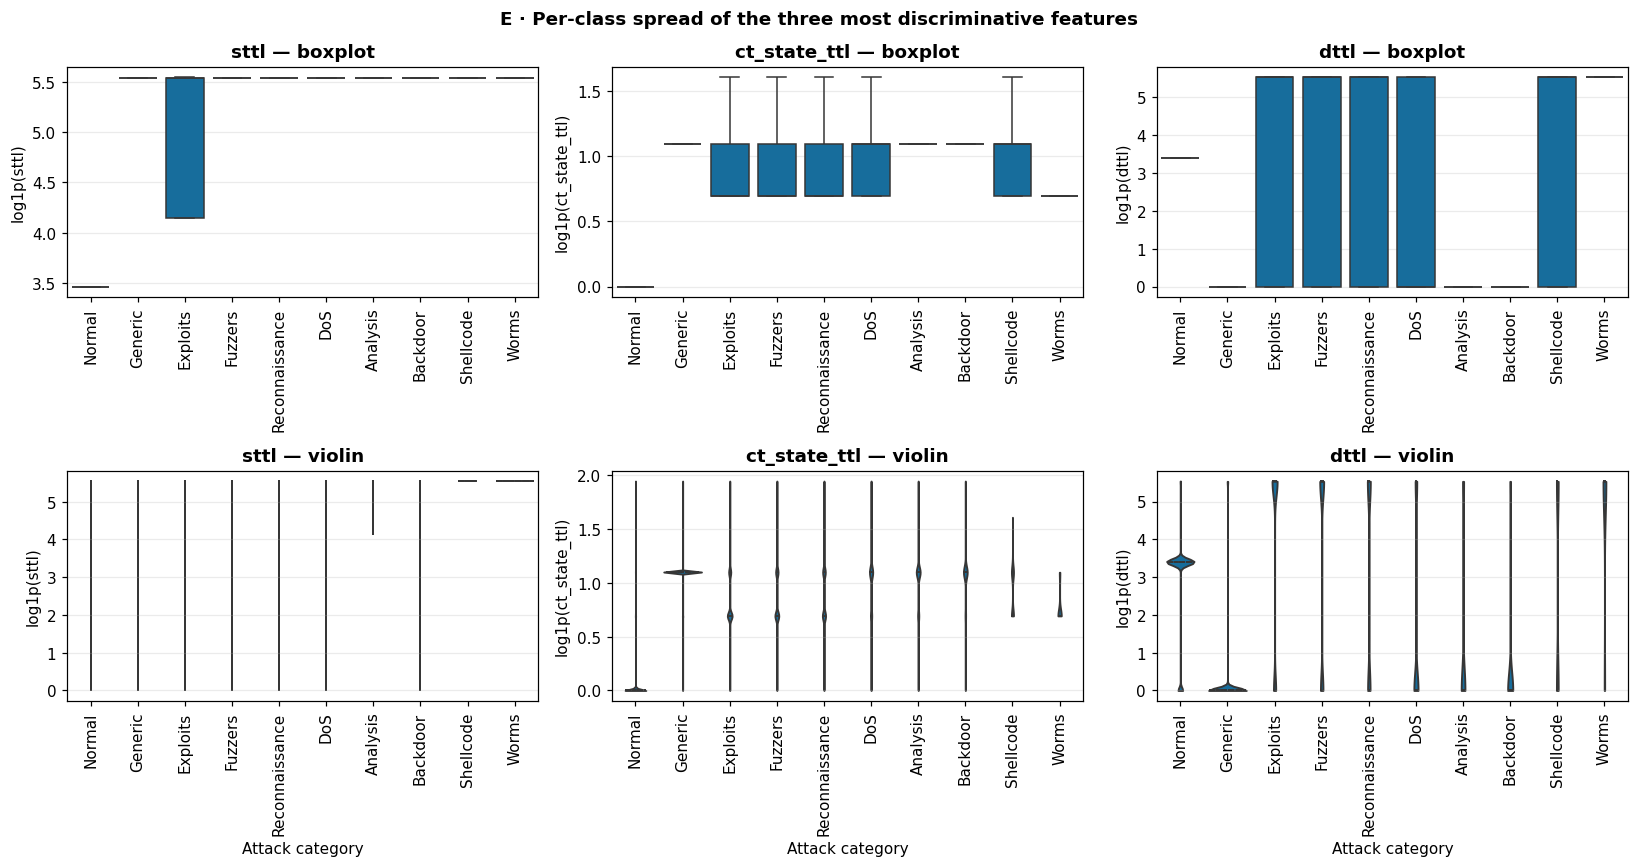


Reading: Classes whose boxes sit at the same level on every feature are the ones our confusion matrix will confuse. Watch Analysis, Backdoor and DoS against Exploits in particular.


In [34]:
# Boxplots and violins for the three strongest features, by attack category.
if TARGET_MULTI:
    order = df[TARGET_MULTI].value_counts().index.tolist()
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for j, c in enumerate(TOPK[:3]):
        s = np.log1p(df[c].replace([np.inf, -np.inf], np.nan).clip(lower=0))
        t = pd.DataFrame({TARGET_MULTI: df[TARGET_MULTI], "v": s}).dropna()

        sns.boxplot(data=t, x=TARGET_MULTI, y="v", order=order,
                    ax=axes[0, j], showfliers=False)
        axes[0, j].set_title(f"{c} — boxplot")
        axes[0, j].set_xlabel(""); axes[0, j].set_ylabel(f"log1p({c})")
        axes[0, j].tick_params(axis="x", rotation=90)

        sns.violinplot(data=t, x=TARGET_MULTI, y="v", order=order,
                       ax=axes[1, j], cut=0, inner="quartile")
        axes[1, j].set_title(f"{c} — violin")
        axes[1, j].set_xlabel("Attack category"); axes[1, j].set_ylabel(f"log1p({c})")
        axes[1, j].tick_params(axis="x", rotation=90)

    fig.suptitle("E · Per-class spread of the three most discriminative features",
                 fontweight="bold")
    save(fig, "E_box_violin"); plt.show()
    reading("Classes whose boxes sit at the same level on every feature are the "
            "ones our confusion matrix will confuse. Watch Analysis, Backdoor "
            "and DoS against Exploits in particular.")

## F · Correlation and redundancy

A heatmap of the numeric features plus an explicit list of redundant ones. For
UNSW-NB15 the `ct_*` connection counters are the usual offenders, because several
of them count overlapping things.

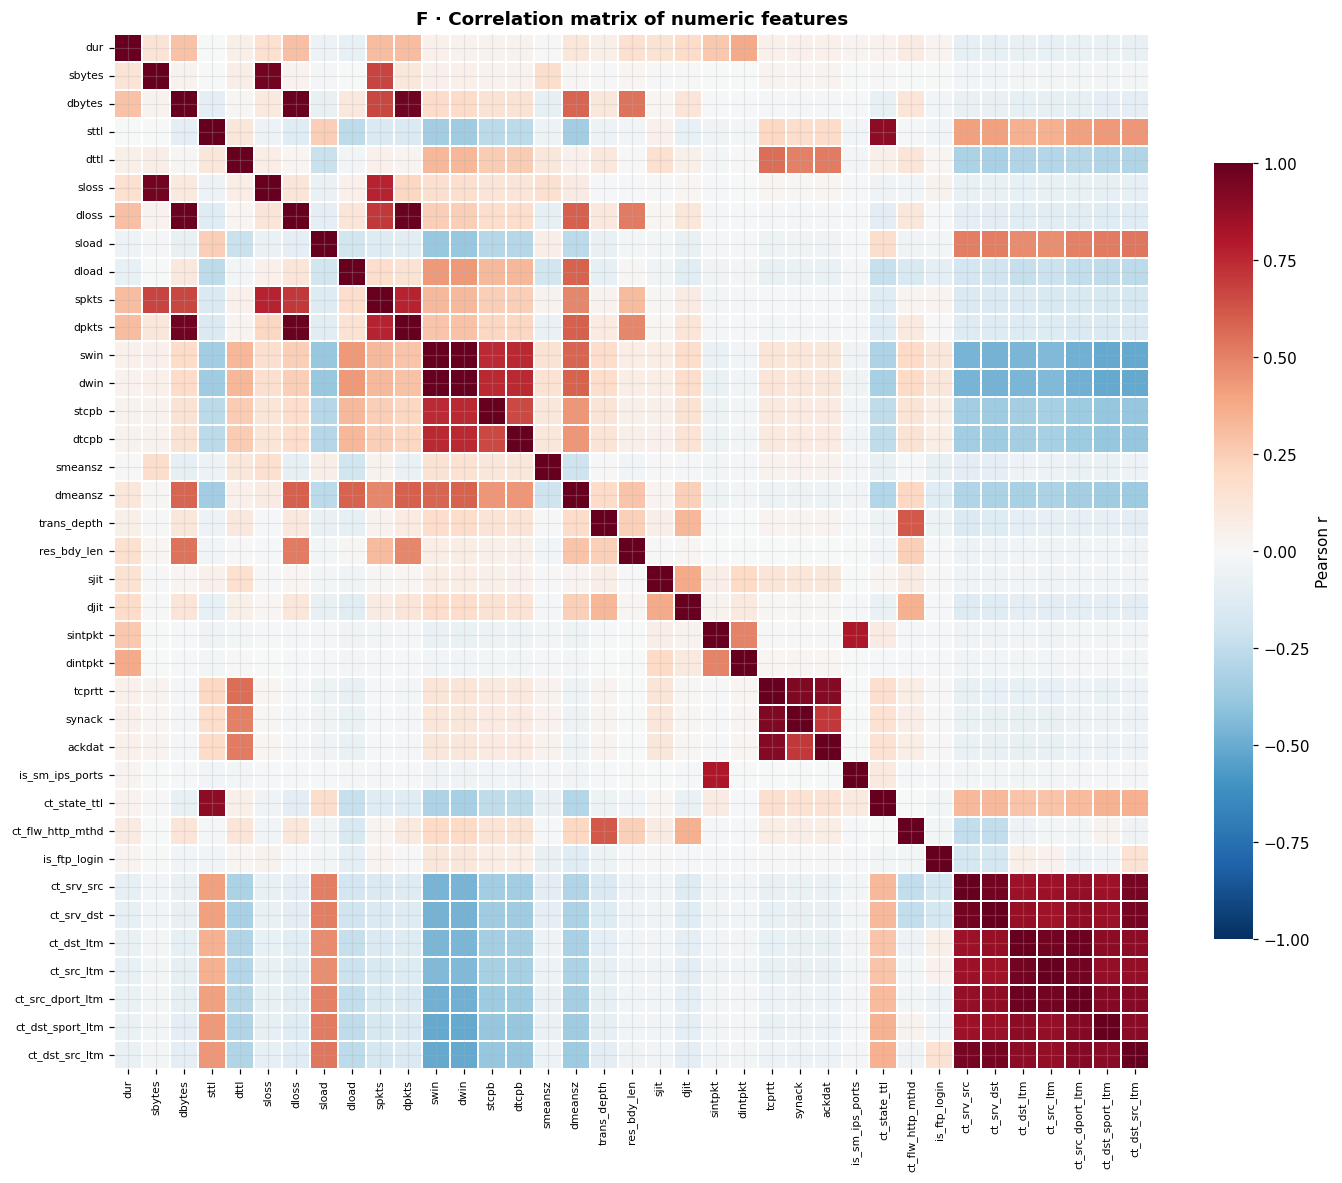


Reading: Red blocks off the diagonal are groups of features measuring nearly the same thing. The ct_* counters form one such block, and the source/destination byte and packet pairs form another.


In [35]:
cm_full = df[FEAT_NUM].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm_full, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.3, cbar_kws={"shrink": .7, "label": "Pearson r"},
            xticklabels=True, yticklabels=True, ax=ax)
ax.set_title("F · Correlation matrix of numeric features", fontweight="bold")
ax.tick_params(labelsize=7)
save(fig, "F_correlation_heatmap"); plt.show()
reading("Red blocks off the diagonal are groups of features measuring nearly "
        "the same thing. The ct_* counters form one such block, and the "
        "source/destination byte and packet pairs form another.")

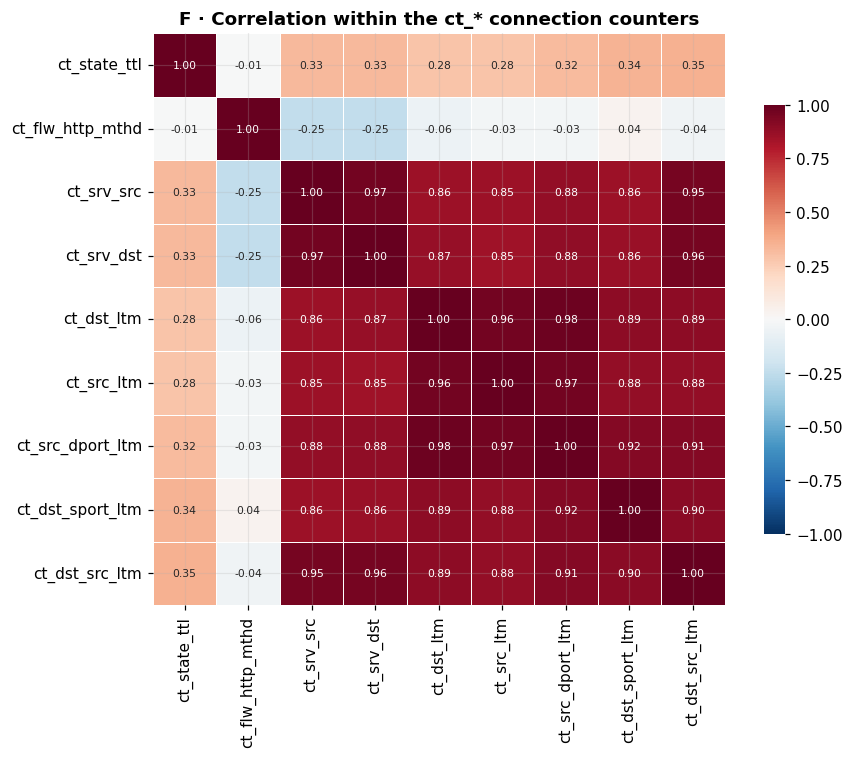


Reading: These counters are derived from overlapping windows of recent connections, so high mutual correlation is expected. Dropping one of each strongly correlated pair stabilises SHAP values in Task 3.

Redundant candidates from §C4 (|r| >= 0.95): ['ct_dst_src_ltm', 'ct_src_dport_ltm', 'ct_src_ltm', 'ct_srv_dst', 'dloss', 'dpkts', 'dwin', 'sloss']


In [36]:
# Zoom on the ct_* family, where the redundancy concentrates.
ct = [c for c in FEAT_NUM if c.startswith("ct_")]
if len(ct) >= 2:
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sns.heatmap(df[ct].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, square=True, linewidths=.4,
                annot_kws={"size": 7}, cbar_kws={"shrink": .75}, ax=ax)
    ax.set_title("F · Correlation within the ct_* connection counters",
                 fontweight="bold")
    save(fig, "F_ct_correlation"); plt.show()
    reading("These counters are derived from overlapping windows of recent "
            "connections, so high mutual correlation is expected. Dropping one "
            "of each strongly correlated pair stabilises SHAP values in Task 3.")

print(f"\nRedundant candidates from §C4 (|r| >= {CORR_T}): {redundant}")

## G · 2D projection — PCA, t-SNE, UMAP

Do the classes separate in a low-dimensional view? This is the figure that
previews how hard the problem is.

t-SNE is O(n²)-ish, so we work on a **stratified subsample** — every class is
represented, including the rare ones. The subsample is for visualisation only.

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

SUB_N = 6000
y_all = df[TARGET_MULTI] if TARGET_MULTI else df[TARGET_BIN]

# Stratified subsample: at most SUB_N rows, every class kept.
per = max(50, SUB_N // y_all.nunique())
idx = (df.groupby(y_all, group_keys=False)
         .apply(lambda g: g.sample(min(len(g), per), random_state=SEED)).index)

Xp = Xs.loc[idx]
yp = y_all.loc[idx]
Xz = StandardScaler().fit_transform(Xp)

print(f"Projection subsample: {Xz.shape[0]:,} rows x {Xz.shape[1]} features")
print(yp.value_counts().to_string())

Projection subsample: 5,340 rows x 37 features
attack_cat
Analysis          600
Backdoor          600
DoS               600
Exploits          600
Fuzzers           600
Generic           600
Normal            600
Reconnaissance    600
Shellcode         487
Worms              53


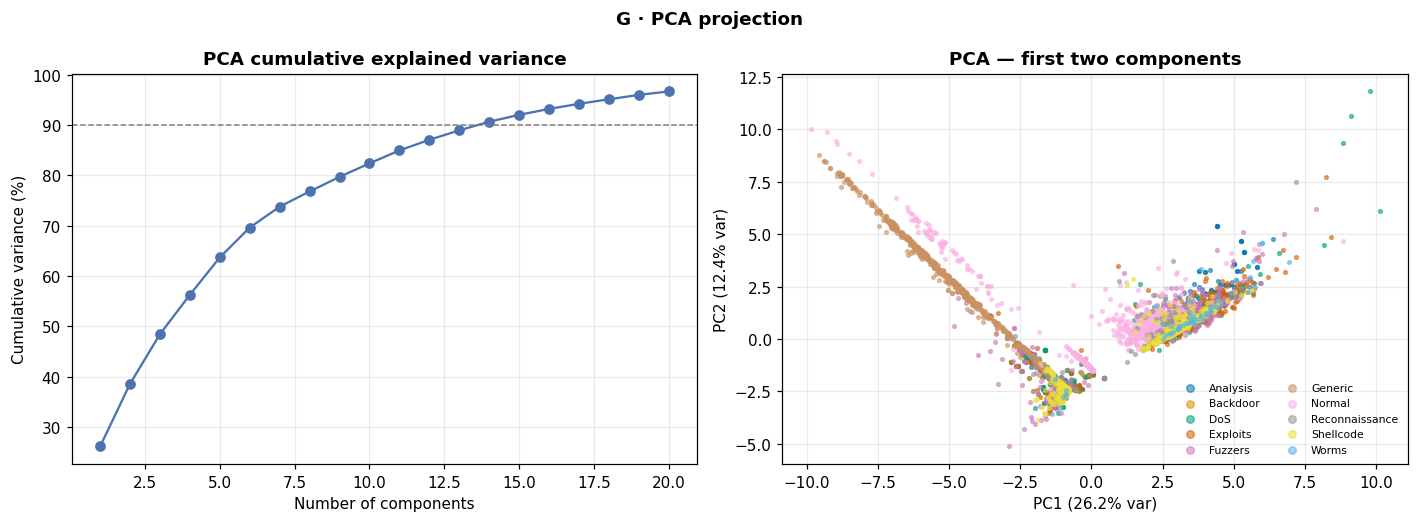


Reading: 14 components explain 90% of the variance, so the feature space is genuinely lower-dimensional than its 37 columns suggest. The scatter shows the classes are not linearly separable in two dimensions — which is why we need a non-linear model.


In [38]:
pca = PCA(n_components=min(20, Xz.shape[1]), random_state=SEED)
Zp = pca.fit_transform(Xz)
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(range(1, len(ev) + 1), np.cumsum(ev) * 100, "o-", color="#4C72B0")
axes[0].axhline(90, ls="--", c="grey", lw=1)
axes[0].set_title("PCA cumulative explained variance")
axes[0].set_xlabel("Number of components"); axes[0].set_ylabel("Cumulative variance (%)")

for c in yp.value_counts().index:
    m = (yp == c).values
    axes[1].scatter(Zp[m, 0], Zp[m, 1], s=6, alpha=.55, label=str(c))
axes[1].set_title("PCA — first two components")
axes[1].set_xlabel(f"PC1 ({ev[0]*100:.1f}% var)")
axes[1].set_ylabel(f"PC2 ({ev[1]*100:.1f}% var)")
axes[1].legend(fontsize=7, markerscale=2, ncol=2)

fig.suptitle("G · PCA projection", fontweight="bold")
save(fig, "G_pca"); plt.show()

k90 = int(np.argmax(np.cumsum(ev) >= .90) + 1)
reading(f"{k90} components explain 90% of the variance, so the feature space is "
        f"genuinely lower-dimensional than its {Xz.shape[1]} columns suggest. "
        "The scatter shows the classes are not linearly separable in two "
        "dimensions — which is why we need a non-linear model.")

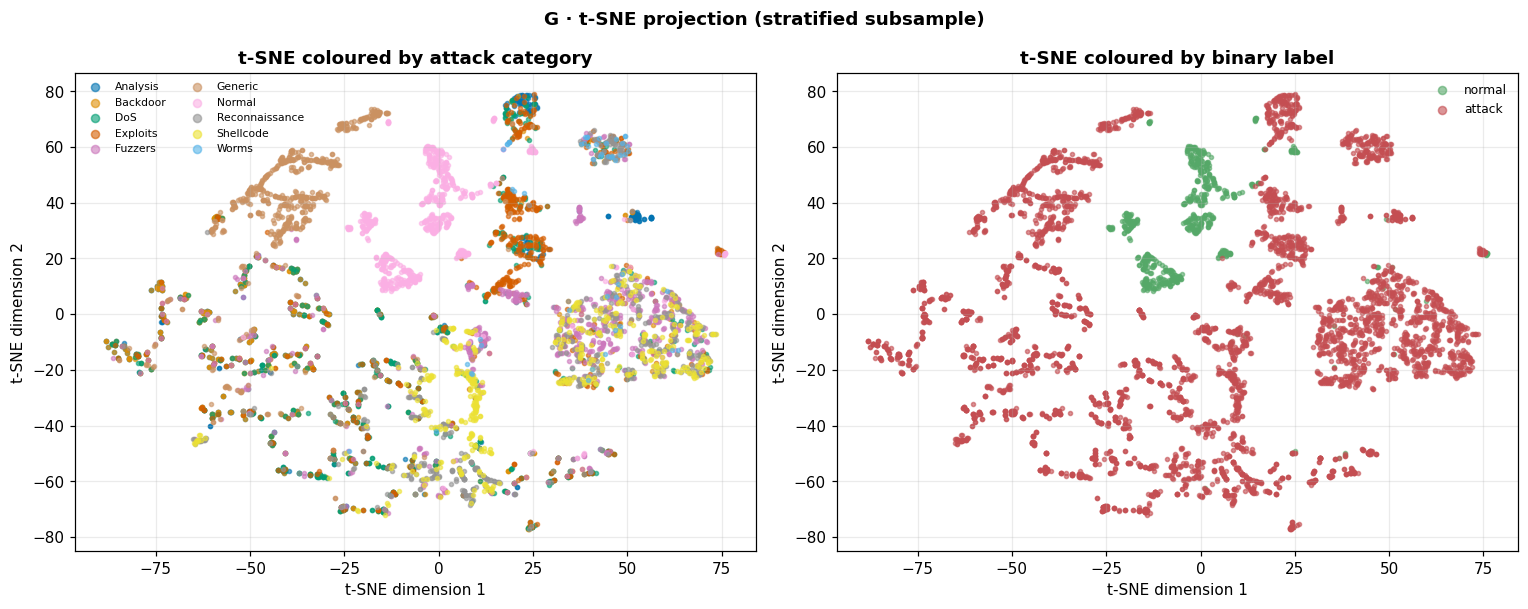


Reading: Distinct clusters mean some attack families are easy to tell apart on flow features alone. Where attack points sit inside normal clusters, flow features are insufficient — and those are exactly the flows we hope host topology will help classify.


In [39]:
# t-SNE on the PCA-reduced data: standard practice, much faster, less noise.
ts = TSNE(n_components=2, perplexity=30, init="pca",
          learning_rate="auto", random_state=SEED)
Zt = ts.fit_transform(Zp[:, :min(20, Zp.shape[1])])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

for c in yp.value_counts().index:
    m = (yp == c).values
    axes[0].scatter(Zt[m, 0], Zt[m, 1], s=7, alpha=.6, label=str(c))
axes[0].set_title("t-SNE coloured by attack category")
axes[0].set_xlabel("t-SNE dimension 1"); axes[0].set_ylabel("t-SNE dimension 2")
axes[0].legend(fontsize=7, markerscale=2, ncol=2)

yb = df[TARGET_BIN].loc[idx].values
for lab, color, name in [(0, "#55A868", "normal"), (1, "#C44E52", "attack")]:
    m = yb == lab
    axes[1].scatter(Zt[m, 0], Zt[m, 1], s=7, alpha=.6, c=color, label=name)
axes[1].set_title("t-SNE coloured by binary label")
axes[1].set_xlabel("t-SNE dimension 1"); axes[1].set_ylabel("t-SNE dimension 2")
axes[1].legend(fontsize=8, markerscale=2)

fig.suptitle("G · t-SNE projection (stratified subsample)", fontweight="bold")
save(fig, "G_tsne"); plt.show()
reading("Distinct clusters mean some attack families are easy to tell apart on "
        "flow features alone. Where attack points sit inside normal clusters, "
        "flow features are insufficient — and those are exactly the flows we "
        "hope host topology will help classify.")

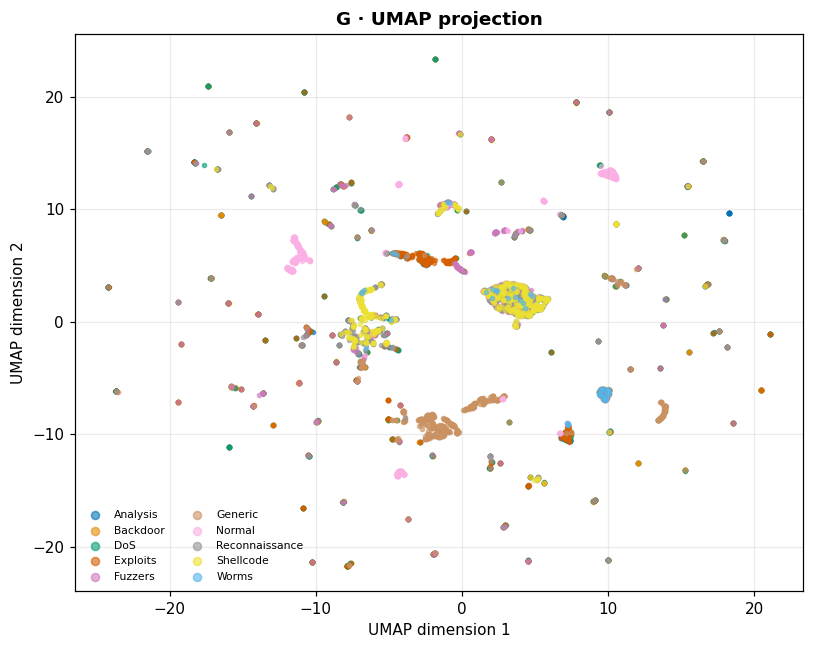


Reading: UMAP preserves more global structure than t-SNE; comparing the two shows which clusters are robust to the choice of projection.


In [55]:
# UMAP is optional on Kaggle; skip gracefully if the package is absent.
try:
    import umap
    um = umap.UMAP(n_neighbors=15, min_dist=.1, random_state=SEED)
    Zu = um.fit_transform(Xz)

    fig, ax = plt.subplots(figsize=(7.5, 6))
    for c in yp.value_counts().index:
        m = (yp == c).values
        ax.scatter(Zu[m, 0], Zu[m, 1], s=7, alpha=.6, label=str(c))
    ax.set_title("G · UMAP projection", fontweight="bold")
    ax.set_xlabel("UMAP dimension 1"); ax.set_ylabel("UMAP dimension 2")
    ax.legend(fontsize=7, markerscale=2, ncol=2)
    save(fig, "G_umap"); plt.show()
    reading("UMAP preserves more global structure than t-SNE; comparing the two "
            "shows which clusters are robust to the choice of projection.")
except ImportError:
    print("umap-learn not installed — skipping UMAP (PCA and t-SNE above satisfy §G).")
    print("To enable: pip install umap-learn")

## H · Interactive plots

Plotly figures with titles, axis labels and hover detail. On Kaggle these render
inline; export the notebook with outputs so they survive in the submission.

In [57]:
try:
    import plotly.express as px
    import plotly.io as pio
    # "notebook_connected" loads plotly.js from a CDN, so the figures survive in
    # a saved and shared Kaggle notebook. Falls back to the default renderer.
    try:
        pio.renderers.default = "notebook_connected"
    except Exception:
        pass
    PLOTLY = True
except ImportError:
    print("plotly not installed — run: pip install plotly")
    PLOTLY = False

if PLOTLY and D is not None:
    # Build an explicit two-column frame so the x axis name is never in doubt.
    Dp = pd.DataFrame({"attack_category": D.index.astype(str),
                       "flows": D["count"].values})
    f1 = px.bar(Dp, x="attack_category", y="flows", log_y=True,
                color="flows", color_continuous_scale="Viridis",
                title="H1 · Class distribution (log scale) — hover for exact counts",
                labels={"flows": "Number of flows",
                        "attack_category": "Attack category"})
    f1.update_layout(height=460)
    f1.show()
    print("Reading: the log axis makes Worms and Shellcode visible; hover gives "
          "the exact counts that the report quotes.")

Reading: the log axis makes Worms and Shellcode visible; hover gives the exact counts that the report quotes.


In [58]:
if PLOTLY:
    samp = df.loc[idx].copy()
    xcol, ycol = TOPK[0], TOPK[1]
    samp["_x"] = np.log1p(samp[xcol].clip(lower=0))
    samp["_y"] = np.log1p(samp[ycol].clip(lower=0))

    f2 = px.scatter(
        samp, x="_x", y="_y",
        color=TARGET_MULTI if TARGET_MULTI else TARGET_BIN,
        opacity=.65,
        title=f"H2 · {xcol} vs {ycol} by class (log1p scale)",
        labels={"_x": f"log1p({xcol})", "_y": f"log1p({ycol})"},
        hover_data=[c for c in [TARGET_BIN, "proto", "service", "state"]
                    if c in samp.columns],
    )
    f2.update_traces(marker=dict(size=5))
    f2.update_layout(height=560)
    f2.show()
    print("Reading: the two strongest features alone already separate several "
          "attack families, which sets the bar our graph model must clear.")

Reading: the two strongest features alone already separate several attack families, which sets the bar our graph model must clear.


In [59]:
if PLOTLY and "proto" in df.columns:
    ct_tab = (df.groupby(["proto", TARGET_BIN]).size()
                .rename("flows").reset_index())
    top_proto = df["proto"].value_counts().head(12).index
    ct_tab = ct_tab[ct_tab["proto"].isin(top_proto)]
    ct_tab[TARGET_BIN] = ct_tab[TARGET_BIN].map({0: "normal", 1: "attack"})

    f3 = px.bar(ct_tab, x="proto", y="flows", color=TARGET_BIN, barmode="group",
                log_y=True,
                title="H3 · Normal vs attack flows per protocol (top 12 protocols)",
                labels={"proto": "Protocol", "flows": "Number of flows",
                        TARGET_BIN: "Class"})
    f3.update_layout(height=470)
    f3.show()
    print("Reading: protocols whose bars are overwhelmingly one class are "
          "strong signals on their own — useful for baselines, and a reminder "
          "that categorical encoding must be fit on training data only.")

Reading: protocols whose bars are overwhelmingly one class are strong signals on their own — useful for baselines, and a reminder that categorical encoding must be fit on training data only.


---

# Project-specific analysis

The three sections below are not in the generic A–H list. They exist because our
track builds a **host graph**, and these are the facts that decide whether that
is feasible and whether it is honest.

## P1 · Host cardinality — can we build a graph at all?

For a flow-as-edge graph we need hosts as nodes. This section counts them,
measures how concentrated the traffic is, and reports whether the resulting graph
is rich enough to be worth a GNN.

In [60]:
if not HAS_IP:
    print("=" * 68)
    print("SKIPPED — no srcip/dstip columns in the loaded files.")
    print("This is itself a Task 1 finding: the partitioned CSVs cannot support")
    print("a host graph. Record it in the report and attach the full")
    print("UNSW-NB15_1..4.csv files before Task 2.")
    print("=" * 68)
else:
    src_n  = df["srcip"].nunique()
    dst_n  = df["dstip"].nunique()
    hosts  = pd.concat([df["srcip"], df["dstip"]]).nunique()
    edges  = df.groupby(["srcip", "dstip"]).size()

    print(f"Distinct source hosts      : {src_n:,}")
    print(f"Distinct destination hosts : {dst_n:,}")
    print(f"Distinct hosts (nodes)     : {hosts:,}")
    print(f"Distinct host pairs        : {len(edges):,}")
    print(f"Total flows (edges)        : {len(df):,}")
    print(f"Mean flows per host pair   : {len(df)/len(edges):,.1f}")
    print(f"Graph density              : {len(edges)/(hosts*(hosts-1)):.6f}")

    P1 = pd.DataFrame({
        "metric": ["source hosts", "destination hosts", "total nodes",
                   "distinct host pairs", "flows (edges)", "mean flows per pair"],
        "value":  [src_n, dst_n, hosts, len(edges), len(df),
                   round(len(df)/len(edges), 2)],
    }).set_index("metric")
    dump(P1, "P1_host_cardinality")
    print("\nReading: with", f"{hosts:,}", "nodes and", f"{len(edges):,}",
          "distinct host pairs, the graph is sparse and multi-edge — several",
          "flows share one host pair. This is a genuine topology, not an",
          "invented one, which is what the brief requires for the graph bonus.")

Distinct source hosts      : 42
Distinct destination hosts : 46
Distinct hosts (nodes)     : 48
Distinct host pairs        : 292
Total flows (edges)        : 700,000
Mean flows per host pair   : 2,397.3
Graph density              : 0.129433

Reading: with 48 nodes and 292 distinct host pairs, the graph is sparse and multi-edge — several flows share one host pair. This is a genuine topology, not an invented one, which is what the brief requires for the graph bonus.


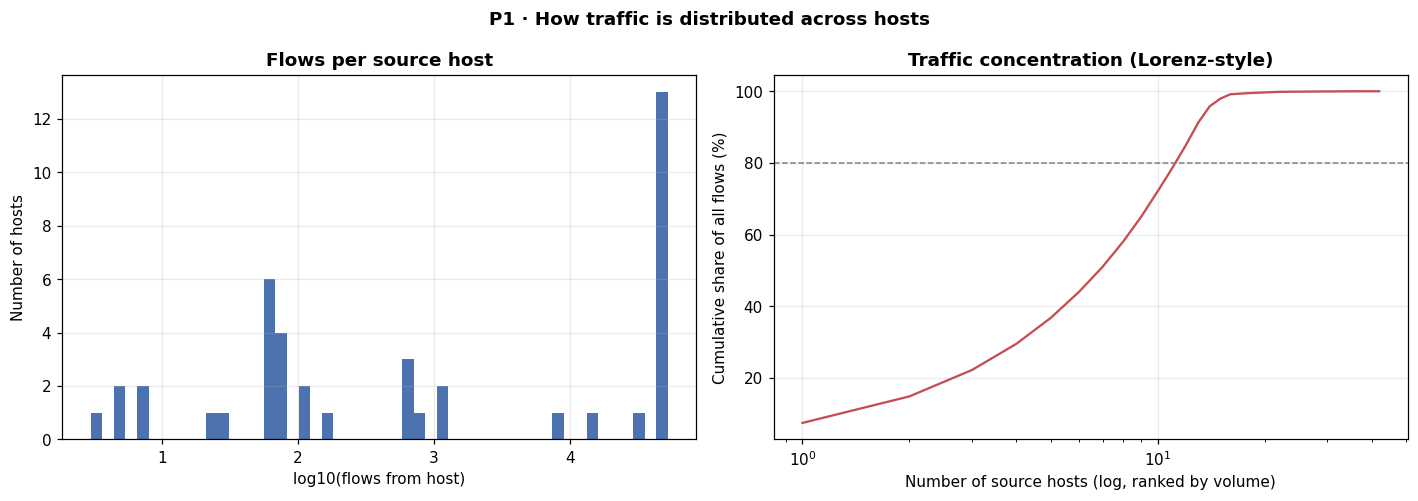


Reading: 12 source host(s) account for 80% of all flows (28.57% of hosts). The traffic is heavily concentrated, which means a host-disjoint split must be built deliberately rather than by random host assignment — see §P3.


In [61]:
if HAS_IP:
    flows_per_src = df["srcip"].value_counts()
    flows_per_dst = df["dstip"].value_counts()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

    axes[0].hist(np.log10(flows_per_src.values), bins=50, color="#4C72B0")
    axes[0].set_title("Flows per source host")
    axes[0].set_xlabel("log10(flows from host)"); axes[0].set_ylabel("Number of hosts")

    cum = np.cumsum(flows_per_src.sort_values(ascending=False).values) / len(df) * 100
    axes[1].plot(np.arange(1, len(cum) + 1), cum, color="#C44E52")
    axes[1].set_xscale("log")
    axes[1].axhline(80, ls="--", c="grey", lw=1)
    axes[1].set_title("Traffic concentration (Lorenz-style)")
    axes[1].set_xlabel("Number of source hosts (log, ranked by volume)")
    axes[1].set_ylabel("Cumulative share of all flows (%)")

    fig.suptitle("P1 · How traffic is distributed across hosts", fontweight="bold")
    save(fig, "P1_host_distribution"); plt.show()

    n80 = int(np.argmax(cum >= 80) + 1)
    reading(f"{n80} source host(s) account for 80% of all flows "
            f"({n80/len(flows_per_src)*100:.2f}% of hosts). The traffic is "
            "heavily concentrated, which means a host-disjoint split must be "
            "built deliberately rather than by random host assignment — see §P3.")

## P2 · Identifier leakage — the evidence

The brief names this dataset specifically: *remove ID-like columns … they let the
model memorise the trace.* This section produces the **evidence** for that rule
rather than merely asserting it.

If the attack traffic originates from a small set of IP addresses, then a model
given `srcip` as a feature learns the addresses, not the attacks. Showing this is
the most persuasive single figure we can put in the Task 1 report.

In [62]:
if not HAS_IP:
    print("Skipped — no IP columns. State the rule in the report by citation "
          "(§6.2 of the brief) rather than by measurement.")
else:
    atk = df[df[TARGET_BIN] == 1]
    nor = df[df[TARGET_BIN] == 0]

    atk_src = atk["srcip"].nunique()
    nor_src = nor["srcip"].nunique()
    overlap = len(set(atk["srcip"].unique()) & set(nor["srcip"].unique()))

    print(f"Source hosts sending ANY attack flow   : {atk_src:,}")
    print(f"Source hosts sending ANY normal flow   : {nor_src:,}")
    print(f"Hosts sending both                     : {overlap:,}")
    print(f"Hosts sending ONLY attack traffic      : {atk_src - overlap:,}")

    top_atk = atk["srcip"].value_counts().head(10)
    share = top_atk.sum() / len(atk) * 100
    print(f"\nTop 10 attacking source IPs cover {share:.2f}% of all attack flows:")
    print(top_atk.to_string())

    # Purity: for each host, what fraction of its flows are attacks?
    purity = df.groupby("srcip")[TARGET_BIN].mean()
    pure_atk = (purity == 1).sum()
    pure_nor = (purity == 0).sum()
    print(f"\nHosts that are 100% attack traffic : {pure_atk:,}")
    print(f"Hosts that are 100% normal traffic : {pure_nor:,}")
    print(f"Hosts that are mixed               : {((purity>0)&(purity<1)).sum():,}")

Source hosts sending ANY attack flow   : 4
Source hosts sending ANY normal flow   : 42
Hosts sending both                     : 4
Hosts sending ONLY attack traffic      : 0

Top 10 attacking source IPs cover 100.00% of all attack flows:
srcip
175.45.176.1    42466
175.45.176.3    39554
175.45.176.0    12011
175.45.176.2     5890

Hosts that are 100% attack traffic : 0
Hosts that are 100% normal traffic : 38
Hosts that are mixed               : 4


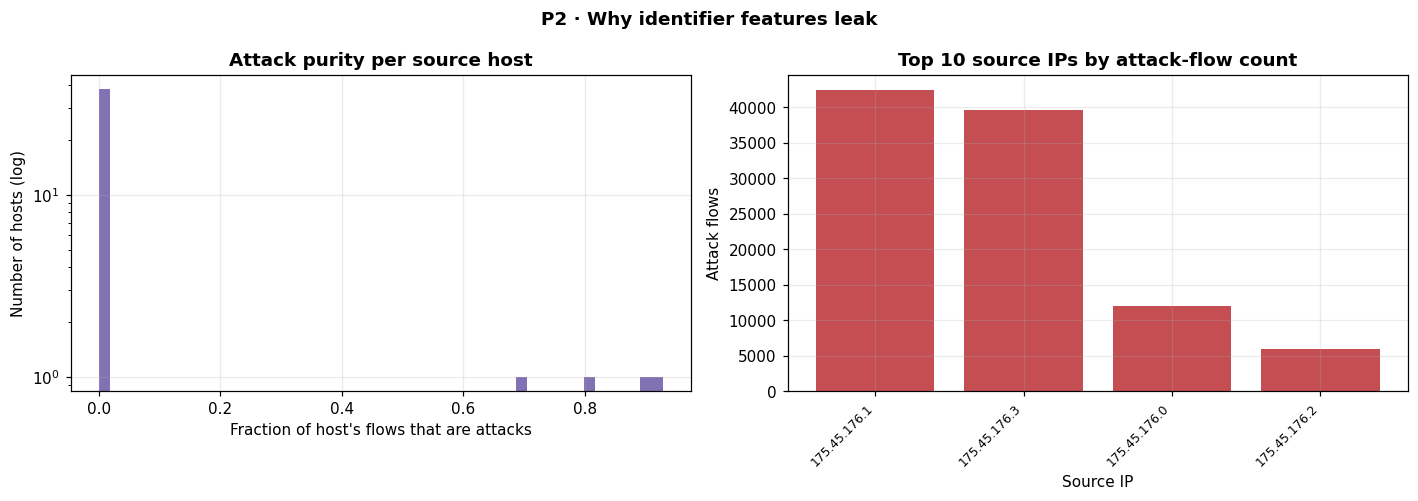


Reading: The purity histogram is bimodal: most hosts are entirely attack or entirely normal, and only 4 are mixed. The top 10 attacking IPs alone cover 100.0% of attack flows. A model given srcip would therefore reach near-perfect accuracy by memorising addresses, with no understanding of attack behaviour. This is why srcip, dstip, sport, dsport, stime and ltime are excluded from the feature vector — and why they are still used to define graph nodes and edges, which carries no label information.


In [63]:
if HAS_IP:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

    axes[0].hist(purity.values, bins=50, color="#8172B3")
    axes[0].set_yscale("log")
    axes[0].set_title("Attack purity per source host")
    axes[0].set_xlabel("Fraction of host's flows that are attacks")
    axes[0].set_ylabel("Number of hosts (log)")

    axes[1].bar(range(len(top_atk)), top_atk.values, color="#C44E52")
    axes[1].set_xticks(range(len(top_atk)))
    axes[1].set_xticklabels(top_atk.index, rotation=45, ha="right", fontsize=8)
    axes[1].set_title("Top 10 source IPs by attack-flow count")
    axes[1].set_xlabel("Source IP"); axes[1].set_ylabel("Attack flows")

    fig.suptitle("P2 · Why identifier features leak", fontweight="bold")
    save(fig, "P2_identifier_leakage"); plt.show()

    reading(f"The purity histogram is bimodal: most hosts are entirely attack or "
            f"entirely normal, and only {((purity>0)&(purity<1)).sum():,} are mixed. "
            f"The top 10 attacking IPs alone cover {share:.1f}% of attack flows. "
            "A model given srcip would therefore reach near-perfect accuracy by "
            "memorising addresses, with no understanding of attack behaviour. "
            "This is why srcip, dstip, sport, dsport, stime and ltime are "
            "excluded from the feature vector — and why they are still used to "
            "define graph nodes and edges, which carries no label information.")

In [65]:
# Quantify the leak: a single decision tree on identifiers alone.
if HAS_IP:
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.model_selection import cross_val_score

    ids = df[["srcip", "dstip"]].astype("category").apply(lambda s: s.cat.codes)
    sub = np.random.RandomState(SEED).choice(len(df), min(80_000, len(df)), replace=False)

    sc = cross_val_score(
        DecisionTreeClassifier(max_depth=12, random_state=SEED),
        ids.iloc[sub], df[TARGET_BIN].iloc[sub], cv=3, scoring="f1_macro")

    print(f"Macro-F1 using ONLY srcip + dstip as features: "
          f"{sc.mean():.4f} +/- {sc.std():.4f}")
    print("\nReading: identifier columns alone achieve this macro-F1 while")
    print("learning nothing about network behaviour. Any reported score that")
    print("includes them as features is measuring memorisation, not detection.")
    print("This single number justifies our entire preprocessing decision.")

Macro-F1 using ONLY srcip + dstip as features: 0.9647 +/- 0.0013

Reading: identifier columns alone achieve this macro-F1 while
learning nothing about network behaviour. Any reported score that
includes them as features is measuring memorisation, not detection.
This single number justifies our entire preprocessing decision.


## P3 · Three-way host-disjoint split feasibility

The course deck released today makes **validation mandatory**: training fits
weights, validation chooses settings and the checkpoint, test evaluates the locked
pipeline. Combined with the host-grouping rule, we need a **three-way
host-disjoint split**.

This section checks it is achievable: can we partition hosts 70/15/15 and still
get every attack class represented in all three parts? If a rare class lives on a
single host, the answer is no, and we need to know tonight.

In [66]:
if not HAS_IP:
    print("Skipped — needs IP columns. Carry this check into Task 2 once the "
          "full CSVs are attached.")
else:
    from sklearn.model_selection import GroupShuffleSplit

    groups = df["srcip"].values
    y = df[TARGET_MULTI].values if TARGET_MULTI else df[TARGET_BIN].values

    # 70 / 15 / 15 by host, nested so no host appears in two parts.
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
    tr_i, rest_i = next(gss1.split(df, y, groups))

    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    va_rel, te_rel = next(gss2.split(df.iloc[rest_i], y[rest_i], groups[rest_i]))
    va_i, te_i = rest_i[va_rel], rest_i[te_rel]

    parts = {"train": tr_i, "val": va_i, "test": te_i}

    print("Split sizes:")
    for k, v in parts.items():
        print(f"  {k:<6} {len(v):>9,} flows  ({len(v)/len(df)*100:5.2f}%)  "
              f"{pd.Series(groups[v]).nunique():>6,} hosts")

    # The critical assertion: no host crosses a boundary.
    sets = {k: set(groups[v]) for k, v in parts.items()}
    leaks = {f"{a}-{b}": len(sets[a] & sets[b])
             for a, b in [("train","val"), ("train","test"), ("val","test")]}
    print("\nHost overlap between parts (must all be 0):")
    for k, v in leaks.items():
        print(f"  {k:<12} {v}")
    assert all(v == 0 for v in leaks.values()), "HOST LEAK — split is invalid"
    print("\n  PASS — the split is host-disjoint.")

Split sizes:
  train    505,219 flows  (72.17%)      29 hosts
  val       89,839 flows  (12.83%)       6 hosts
  test     104,942 flows  (14.99%)       7 hosts

Host overlap between parts (must all be 0):
  train-val    0
  train-test   0
  val-test     0

  PASS — the split is host-disjoint.


In [68]:
if HAS_IP and TARGET_MULTI:
    cov = pd.DataFrame({
        k: pd.Series(y[v]).value_counts() for k, v in parts.items()
    }).fillna(0).astype(int)
    cov["train_%"] = (cov["train"] / cov["train"].sum() * 100).round(2)
    cov["test_%"]  = (cov["test"]  / cov["test"].sum()  * 100).round(2)
    dump(cov, "P3_split_class_coverage")

    missing = cov[(cov[["train", "val", "test"]] == 0).any(axis=1)]

    print("Class coverage across the host-disjoint split:\n")
    print(cov.to_string())

    if len(missing):
        print("\n" + "=" * 68)
        print("WARNING — these classes are ABSENT from at least one part:")
        print(missing.index.tolist())
        print("Cause: the class lives on too few distinct hosts to spread across")
        print("three parts. Options: (a) group by a coarser key such as subnet,")
        print("(b) merge the rarest classes, (c) report binary classification as")
        print("primary and multiclass as secondary. Decide this in Task 2 and")
        print("record the reason in the report.")
        print("=" * 68)
    else:
        print("\n  PASS — every class appears in all three parts.")

    reading("A host-disjoint split changes the class mix between parts, because "
            "attack families are tied to specific hosts. That shift is exactly "
            "what a random split hides, and it is why our scores will sit below "
            "published numbers that used random splits.")

Class coverage across the host-disjoint split:

                 train    val   test  train_%  test_%
Analysis           472      9    464     0.09    0.44
Backdoor           527     50    330     0.10    0.31
DoS                875    434   2590     0.17    2.47
Exploits          3446   2397   7209     0.68    6.87
Fuzzers           2954   1552   4318     0.58    4.11
Generic          33080    362  34123     6.55   32.52
Normal          462753  83949  53377    91.59   50.86
Reconnaissance     981    954   2254     0.19    2.15
Shellcode          124    119    244     0.02    0.23
Worms                7     13     33     0.00    0.03

  PASS — every class appears in all three parts.

Reading: A host-disjoint split changes the class mix between parts, because attack families are tied to specific hosts. That shift is exactly what a random split hides, and it is why our scores will sit below published numbers that used random splits.


In [69]:
# Contrast: how much does a random split inflate the apparent difficulty?
if HAS_IP:
    from sklearn.model_selection import train_test_split
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import f1_score

    sub = np.random.RandomState(SEED).choice(len(df), min(60_000, len(df)), replace=False)
    Xq = Xs.iloc[sub].values
    yq = df[TARGET_BIN].iloc[sub].values
    gq = groups[sub]

    # (a) random split
    Xtr, Xte, ytr, yte = train_test_split(Xq, yq, test_size=.3,
                                          random_state=SEED, stratify=yq)
    m = RandomForestClassifier(n_estimators=120, n_jobs=-1, random_state=SEED)
    m.fit(Xtr, ytr)
    f_rand = f1_score(yte, m.predict(Xte), average="macro")

    # (b) host-grouped split, same model, same budget
    gs = GroupShuffleSplit(n_splits=1, test_size=.3, random_state=SEED)
    a, b = next(gs.split(Xq, yq, gq))
    m2 = RandomForestClassifier(n_estimators=120, n_jobs=-1, random_state=SEED)
    m2.fit(Xq[a], yq[a])
    f_host = f1_score(yq[b], m2.predict(Xq[b]), average="macro")

    print(f"Random split      macro-F1 : {f_rand:.4f}")
    print(f"Host-disjoint     macro-F1 : {f_host:.4f}")
    print(f"Inflation from random split : {(f_rand - f_host):+.4f}")
    print("\nReading: the same model, same features and same budget score")
    print("differently purely because of how the data was split. The gap is the")
    print("size of the optimism in published results that used random splits,")
    print("and it is the empirical core of our research gap.")

Random split      macro-F1 : 0.9807
Host-disjoint     macro-F1 : 0.9722
Inflation from random split : +0.0085

Reading: the same model, same features and same budget score
differently purely because of how the data was split. The gap is the
size of the optimism in published results that used random splits,
and it is the empirical core of our research gap.


---

## Findings and research question

The cell below assembles everything measured above into a findings list for the
Task 1 report, and restates the research question the project will answer.

Read each line, keep what the data actually supports, and delete anything the run
did not produce.

In [71]:
print("=" * 72)
print("TASK 1 — FINDINGS SUMMARY".center(72))
print("=" * 72)

print(f"""
DATA
  Loaded {len(df):,} flows, {df.shape[1]} columns, from the {SOURCE} file shape.
  {len(FEAT_NUM)} numeric and {len(FEAT_CAT)} categorical features are modellable;
  {len(ID_LIKE)} column{'' if len(ID_LIKE) == 1 else 's'} {'is' if len(ID_LIKE) == 1 else 'are'} identifier-like and excluded from the feature vector.

QUALITY
  Missing values: {int(df.isna().sum().sum()):,} across {int((df.isna().sum()>0).sum())} columns.
  Duplicate rows: {int(df.duplicated().sum()):,}.
  Near-constant features: {len(C3)}.
  Feature pairs above |r| = {CORR_T}: {len(pairs)}.
  -> Scaling and imputation must be fit on training data only, and refit inside
     every cross-validation fold.

IMBALANCE""")

if D is not None:
    print(f"""  {D.index[0]} is the largest class ({D.iloc[0]['count']:,} flows);
  {D.index[-1]} is the smallest ({D.iloc[-1]['count']:,} flows).
  Majority-to-minority ratio: {D['count'].max()/D['count'].min():,.0f} : 1.
  -> Overall accuracy is uninformative. We judge on macro-F1 and per-class
     recall, and we expect near-zero recall on the rarest classes unless the
     loss is class-weighted.""")

print("\nSEPARABILITY")
print(f"""  {k90} principal components explain 90% of variance.
  The strongest single feature by ANOVA F is '{rank.iloc[0]['feature']}'.
  t-SNE shows some attack families form distinct clusters while others sit
  inside the normal cloud.
  -> Flat features already separate much of the data, so our baselines will be
     strong and the graph must earn its place on the hard cases.""")

if HAS_IP:
    print("\nGRAPH FEASIBILITY")
    print(f"""  {hosts:,} hosts (nodes), {len(edges):,} distinct host pairs,
  {len(df):,} flows (edges). Mean {len(df)/len(edges):.1f} flows per pair.
  -> A genuine multi-edge host graph exists in this data. We are not inventing
     structure; we are using structure the CSV already contains.

LEAKAGE
  {((purity>0)&(purity<1)).sum():,} of {df['srcip'].nunique():,} source hosts carry mixed traffic;
  the rest are entirely attack or entirely normal.
  Top 10 attacking IPs cover {share:.1f}% of all attack flows.
  -> Identifier columns must never be model features. They are used only to
     define nodes and edges.""")
else:
    print("\nGRAPH FEASIBILITY")
    print("""  BLOCKED — the loaded files contain no IP columns, so no host graph can
  be built from them. The full UNSW-NB15_1..4.csv files are required before
  Task 2. This is a Task 1 finding and belongs in the report.""")

print("\n" + "=" * 72)
print("""
RESEARCH GAP
  Published GNN results on UNSW-NB15 rest on random splits and, in some cases,
  rebalanced subsamples. E-GraphSAGE used a 70/30 split with no stated
  stratification and no validation set; FN-GNN subsampled to 50,000 flows
  rebalanced to 61/39 and split 80/20 at random. Neither split by host or by
  time. Performance under source-disjoint evaluation is therefore largely
  unreported.

RESEARCH QUESTION
  Does a host-topology graph improve macro-F1 over a k-nearest-neighbour
  feature-similarity graph on UNSW-NB15, under the same three-way host-disjoint
  split and the same training budget?
""")
print("=" * 72)

                       TASK 1 — FINDINGS SUMMARY                        

DATA
  Loaded 700,000 flows, 49 columns, from the full file shape.
  37 numeric and 4 categorical features are modellable;
  6 columns are identifier-like and excluded from the feature vector.

QUALITY
  Missing values: 675,596 across 2 columns.
  Duplicate rows: 142,474.
  Near-constant features: 1.
  Feature pairs above |r| = 0.95: 11.
  -> Scaling and imputation must be fit on training data only, and refit inside
     every cross-validation fold.

IMBALANCE
  Normal is the largest class (600,079.0 flows);
  Worms is the smallest (53.0 flows).
  Majority-to-minority ratio: 11,322 : 1.
  -> Overall accuracy is uninformative. We judge on macro-F1 and per-class
     recall, and we expect near-zero recall on the rarest classes unless the
     loss is class-weighted.

SEPARABILITY
  14 principal components explain 90% of variance.
  The strongest single feature by ANOVA F is 'sttl'.
  t-SNE shows some attack familie

In [72]:
# Everything written for the report.
print("Figures saved to ./figures :")
for p in sorted(OUT.glob("*.png")):
    print(f"  {p.name:<34} {p.stat().st_size/1024:>7.0f} KB")

print("\nTables saved to ./tables :")
for p in sorted(TBL.glob("*.csv")):
    print(f"  {p.name:<34} {p.stat().st_size/1024:>7.0f} KB")

print("""
On Kaggle these land in /kaggle/working and appear under the Output tab after
the notebook is saved. Download them from there for the report.""")

Figures saved to ./figures :
  B_top_skew.png                          57 KB
  D_class_balance.png                    128 KB
  E_box_violin.png                       213 KB
  E_histograms.png                       130 KB
  F_correlation_heatmap.png              255 KB
  F_ct_correlation.png                   187 KB
  G_pca.png                              272 KB
  G_tsne.png                             741 KB
  G_umap.png                             169 KB
  P1_host_distribution.png               104 KB
  P2_identifier_leakage.png              104 KB

Tables saved to ./tables :
  A_column_schema.csv                      2 KB
  A_dataset_summary.csv                    0 KB
  B_descriptive_statistics.csv             3 KB
  C1_missing.csv                           0 KB
  C3_near_constant.csv                     0 KB
  C4_correlated_pairs.csv                  0 KB
  D_class_balance.csv                      0 KB
  E_feature_discriminative_rank.csv        1 KB
  P1_host_cardinality.csv      